# Installation Biopython

In [53]:
! pip install Biopython

# 1. Acquisition des donnes (Bio.Entrez)

# 1.1 Import et configuration

In [54]:
from Bio import Entrez
from urllib.error import HTTPError, URLError
import time
import pandas as pd

# Email obligatoire
Entrez.email = "ndongosamba109@gmail.com"


# 1.2 Fonction pour récupérer les articles

In [55]:
def get_pubmed_articles(query, n=100):
    articles = []
    try:
        # Recherche des PMIDs
        handle = Entrez.esearch(db="pubmed", term=query, retmax=n)
        record = Entrez.read(handle)
        handle.close()
        id_list = record["IdList"]
    except Exception as e:
        print("Erreur lors de la recherche :", e)
        return []

    # Boucle de récupération des abstracts
    for pmid in id_list:
        try:
            fetch_handle = Entrez.efetch(db="pubmed", id=pmid, retmode="xml")
            paper = Entrez.read(fetch_handle)
            fetch_handle.close()

            info = paper['PubmedArticle'][0]['MedlineCitation']
            art = info['Article']
            pubdate = art['Journal']['JournalIssue']['PubDate']

            articles.append({
                "PMID": pmid,
                "Titre": art.get('ArticleTitle', ""),
                "Résumé": " ".join(art.get('Abstract', {}).get('AbstractText', [])),
                "Auteurs": [f"{a.get('LastName','')} {a.get('ForeName','')}".strip()
                            for a in art.get('AuthorList', [])],
                "Revue": art['Journal']['Title'],
                "Année": pubdate.get('Year', pubdate.get('MedlineDate', ""))
            })

        except Exception as e:
            print(f"Erreur pour PMID {pmid} :", e)

        # Pause pour respecter la limite NCBI
        time.sleep(0.3)

    return articles


# 1.3 Exécution de la requête

In [56]:
# Requête optimisée pour l’hypertension artérielle
query = "arterial hypertension[Title/Abstract] OR hypertension[Title/Abstract] OR high blood pressure[Title/Abstract]"
articles = get_pubmed_articles(query, n=100)

print(f"Nombre d’articles récupérés : {len(articles)}")


Nombre d’articles récupérés : 100


# 1.4 Sauvegarde en CSV

In [57]:
df = pd.DataFrame(articles)
df.to_csv("pubmed_hypertension.csv", index=False)

print("Fichier CSV sauvegardé : pubmed_hypertension.csv")


Fichier CSV sauvegardé : pubmed_hypertension.csv


In [58]:
df

,PMID,Titre,Résumé,Auteurs,Revue,Année
0,42758898,Effect of Sacubitril/Valsartan versus Angioten...,"Sacubitril/valsartan, the first angiotensin re...","[Li Xueyi, Gao Lige, Guo Wenqing, Li Jiadi]",Journal of cardiovascular pharmacology,2026
1,42758866,The Childhood Liver Disease Research Network's...,Primary sclerosing cholangitis (PSC) is a rare...,"[Mack Cara L, Miethke Alexander G, Hawthorne K...",Hepatology communications,2026
2,42758683,Why only one-quarter of placental fetal growth...,To compare risk factors between preeclampsia-a...,"[Robillard Pierre-Yves, Dekker Gustaaf, Than N...",PloS one,2026
3,42758639,Cardiovascular Morbidity in Acromegaly during ...,Acromegaly has been associated with increased ...,"[Partanen Antti, Peltola Elina, Huhtala Heini,...",European journal of endocrinology,2026
4,42758463,Patient-reported outcomes after surgical treat...,Spontaneous intracranial hypotension (SIH) can...,"[Kapan Ali, Iten Carolina, Ulrich Christian T,...",Acta neurologica Belgica,2026
...,...,...,...,...,...,...
95,42753805,Artificial Intelligence-Driven Norepinephrine ...,Infusion pumps are used in critical care setti...,"[Nair Vidya S, Niranga G D Heshan, Madathil Th...",Methods of information in medicine,2026
96,42753774,Global inequalities in cardiometabolic care an...,Wealth-related inequalities affect cardiometab...,"[Gaye Bamba, Singh Gurbinder, Sattler Elisabet...",The Lancet. Global health,2026
97,42753771,Clinical activity and safety of rilzabrutinib ...,Rilzabrutinib showed robust efficacy and favou...,"[Kuter David J, Ghanima Waleed, Cooper Nichola...",The Lancet. Haematology,2026
98,42753746,Perinatal Risk and Outcomes Among Individuals ...,Pregnant Medicare beneficiaries are typically ...,"[Mbata Osinakachukwu, Fawole Ayodamope, Zimmer...",American journal of perinatology,2026


# 2. Structuration des donnees avec Pandas

# 2.1 Importer les donnees dans un dataFrame

In [59]:
df = pd.DataFrame(articles)
print(df.head())

       PMID                                              Titre  \
0  42758898  Effect of Sacubitril/Valsartan versus Angioten...   
1  42758866  The Childhood Liver Disease Research Network's...   
2  42758683  Why only one-quarter of placental fetal growth...   
3  42758639  Cardiovascular Morbidity in Acromegaly during ...   
4  42758463  Patient-reported outcomes after surgical treat...   

                                              Résumé  \
0  Sacubitril/valsartan, the first angiotensin re...   
1  Primary sclerosing cholangitis (PSC) is a rare...   
2  To compare risk factors between preeclampsia-a...   
3  Acromegaly has been associated with increased ...   
4  Spontaneous intracranial hypotension (SIH) can...   

                                             Auteurs  \
0        [Li Xueyi, Gao Lige, Guo Wenqing, Li Jiadi]   
1  [Mack Cara L, Miethke Alexander G, Hawthorne K...   
2  [Robillard Pierre-Yves, Dekker Gustaaf, Than N...   
3  [Partanen Antti, Peltola Elina, Huhtala

# 2.3 Explorer les donnees

In [60]:
df.tail() # Affiche les dernières lignes du DataFrame

,PMID,Titre,Résumé,Auteurs,Revue,Année
95,42753805,Artificial Intelligence-Driven Norepinephrine ...,Infusion pumps are used in critical care setti...,"[Nair Vidya S, Niranga G D Heshan, Madathil Th...",Methods of information in medicine,2026
96,42753774,Global inequalities in cardiometabolic care an...,Wealth-related inequalities affect cardiometab...,"[Gaye Bamba, Singh Gurbinder, Sattler Elisabet...",The Lancet. Global health,2026
97,42753771,Clinical activity and safety of rilzabrutinib ...,Rilzabrutinib showed robust efficacy and favou...,"[Kuter David J, Ghanima Waleed, Cooper Nichola...",The Lancet. Haematology,2026
98,42753746,Perinatal Risk and Outcomes Among Individuals ...,Pregnant Medicare beneficiaries are typically ...,"[Mbata Osinakachukwu, Fawole Ayodamope, Zimmer...",American journal of perinatology,2026
99,42753491,Are nocturnal home and ambulatory blood pressu...,Nocturnal blood pressure is a strong predictor...,"[Minetto Julian, Espeche Walter, Cerri Gustavo...",Pregnancy hypertension,2026


In [61]:
df.shape # Retourne un tuple (n_lignes, n_colonnes).

(100, 6)

In [62]:
df.info() # Donne un résumé du DataFrame

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 6 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   PMID     100 non-null    object
 1   Titre    100 non-null    object
 2   Résumé   100 non-null    object
 3   Auteurs  100 non-null    object
 4   Revue    100 non-null    object
 5   Année    100 non-null    object
dtypes: object(6)
memory usage: 4.8+ KB


In [63]:
df.memory_usage(deep=True) # Indique la mémoire utilisée par chaque colonne du DataFrame

,0
Index,132
PMID,11300
Titre,24190
Résumé,411666
Auteurs,14496
Revue,14030
Année,10900


# 2.4 Nettoyage

# Doublons

In [64]:
# supprime les doublons
df = df.drop_duplicates(subset="PMID")


# Valeurs manquantes

---



In [65]:
df.fillna(0)

,PMID,Titre,Résumé,Auteurs,Revue,Année
0,42758898,Effect of Sacubitril/Valsartan versus Angioten...,"Sacubitril/valsartan, the first angiotensin re...","[Li Xueyi, Gao Lige, Guo Wenqing, Li Jiadi]",Journal of cardiovascular pharmacology,2026
1,42758866,The Childhood Liver Disease Research Network's...,Primary sclerosing cholangitis (PSC) is a rare...,"[Mack Cara L, Miethke Alexander G, Hawthorne K...",Hepatology communications,2026
2,42758683,Why only one-quarter of placental fetal growth...,To compare risk factors between preeclampsia-a...,"[Robillard Pierre-Yves, Dekker Gustaaf, Than N...",PloS one,2026
3,42758639,Cardiovascular Morbidity in Acromegaly during ...,Acromegaly has been associated with increased ...,"[Partanen Antti, Peltola Elina, Huhtala Heini,...",European journal of endocrinology,2026
4,42758463,Patient-reported outcomes after surgical treat...,Spontaneous intracranial hypotension (SIH) can...,"[Kapan Ali, Iten Carolina, Ulrich Christian T,...",Acta neurologica Belgica,2026
...,...,...,...,...,...,...
95,42753805,Artificial Intelligence-Driven Norepinephrine ...,Infusion pumps are used in critical care setti...,"[Nair Vidya S, Niranga G D Heshan, Madathil Th...",Methods of information in medicine,2026
96,42753774,Global inequalities in cardiometabolic care an...,Wealth-related inequalities affect cardiometab...,"[Gaye Bamba, Singh Gurbinder, Sattler Elisabet...",The Lancet. Global health,2026
97,42753771,Clinical activity and safety of rilzabrutinib ...,Rilzabrutinib showed robust efficacy and favou...,"[Kuter David J, Ghanima Waleed, Cooper Nichola...",The Lancet. Haematology,2026
98,42753746,Perinatal Risk and Outcomes Among Individuals ...,Pregnant Medicare beneficiaries are typically ...,"[Mbata Osinakachukwu, Fawole Ayodamope, Zimmer...",American journal of perinatology,2026


In [66]:
# Remplacer les valeurs manquantes
df = df.fillna("Inconnu")


# Champs incomplets

In [67]:
print(df.isnull().sum())


PMID       0
Titre      0
Résumé     0
Auteurs    0
Revue      0
Année      0
dtype: int64


# 2.5 Reorganisation des colonnes

In [68]:
df = df[["PMID", "Titre", "Résumé", "Auteurs", "Revue", "Année"]]


# 2.6 Extraction automatique des entités biologiques

In [69]:
import re

def extract_entities(text):
    return re.findall(r'\b[A-Z]{3,}\b', text)

df["Entités"] = df["Résumé"].apply(extract_entities)


In [70]:
df

,PMID,Titre,Résumé,Auteurs,Revue,Année,Entités
0,42758898,Effect of Sacubitril/Valsartan versus Angioten...,"Sacubitril/valsartan, the first angiotensin re...","[Li Xueyi, Gao Lige, Guo Wenqing, Li Jiadi]",Journal of cardiovascular pharmacology,2026,"[CNKI, VIP, SAE]"
1,42758866,The Childhood Liver Disease Research Network's...,Primary sclerosing cholangitis (PSC) is a rare...,"[Mack Cara L, Miethke Alexander G, Hawthorne K...",Hepatology communications,2026,"[PSC, PSC, PSC, IBD, AIH, LSM, IBD, IBD, AIH, ..."
2,42758683,Why only one-quarter of placental fetal growth...,To compare risk factors between preeclampsia-a...,"[Robillard Pierre-Yves, Dekker Gustaaf, Than N...",PloS one,2026,"[PFGR, FGR, VFGR, SGA, FGR, PFGR, VFGR, VFGR, ..."
3,42758639,Cardiovascular Morbidity in Acromegaly during ...,Acromegaly has been associated with increased ...,"[Partanen Antti, Peltola Elina, Huhtala Heini,...",European journal of endocrinology,2026,"[CVD, IGF, CVD]"
4,42758463,Patient-reported outcomes after surgical treat...,Spontaneous intracranial hypotension (SIH) can...,"[Kapan Ali, Iten Carolina, Ulrich Christian T,...",Acta neurologica Belgica,2026,"[SIH, SIH, SIH, HIT, HIT, IQR, IQR, IQR, CSF, ..."
...,...,...,...,...,...,...,...
95,42753805,Artificial Intelligence-Driven Norepinephrine ...,Infusion pumps are used in critical care setti...,"[Nair Vidya S, Niranga G D Heshan, Madathil Th...",Methods of information in medicine,2026,"[RFDM, DTCM, RFDM, MAPE, MAPE, DTCM, DTCM, RFD..."
96,42753774,Global inequalities in cardiometabolic care an...,Wealth-related inequalities affect cardiometab...,"[Gaye Bamba, Singh Gurbinder, Sattler Elisabet...",The Lancet. Global health,2026,"[WHO, SII, RII, ASANDE, IQR, SII, RII, RII, RI..."
97,42753771,Clinical activity and safety of rilzabrutinib ...,Rilzabrutinib showed robust efficacy and favou...,"[Kuter David J, Ghanima Waleed, Cooper Nichola...",The Lancet. Haematology,2026,"[IQR, IQR]"
98,42753746,Perinatal Risk and Outcomes Among Individuals ...,Pregnant Medicare beneficiaries are typically ...,"[Mbata Osinakachukwu, Fawole Ayodamope, Zimmer...",American journal of perinatology,2026,"[SMM, SMM]"


# 2.7 Extraction d'autres entites biologiques

# Extraction des facteurs cliniques

In [71]:
# Liste de mots‑clés cliniques
facteurs_cliniques_keywords = [
    "blood pressure", "systolic", "diastolic", "heart rate", "BMI", "obesity",
    "diabetes", "cholesterol", "renal", "creatinine", "smoking", "treatment",
    "angiotensin", "beta-blocker", "diuretic"
]


In [72]:
# Fonction d’extraction
def extract_clinical_factors(text, keywords=facteurs_cliniques_keywords):
    found = []
    for kw in keywords:
        if kw.lower() in text.lower():
            found.append(kw)
    return list(set(found)) #  # éviter les doublons

In [73]:
# Application sur les resumes
df["Facteurs_cliniques"] = df["Résumé"].apply(extract_clinical_factors)


In [74]:
df

,PMID,Titre,Résumé,Auteurs,Revue,Année,Entités,Facteurs_cliniques
0,42758898,Effect of Sacubitril/Valsartan versus Angioten...,"Sacubitril/valsartan, the first angiotensin re...","[Li Xueyi, Gao Lige, Guo Wenqing, Li Jiadi]",Journal of cardiovascular pharmacology,2026,"[CNKI, VIP, SAE]","[angiotensin, diastolic, systolic, blood press..."
1,42758866,The Childhood Liver Disease Research Network's...,Primary sclerosing cholangitis (PSC) is a rare...,"[Mack Cara L, Miethke Alexander G, Hawthorne K...",Hepatology communications,2026,"[PSC, PSC, PSC, IBD, AIH, LSM, IBD, IBD, AIH, ...",[treatment]
2,42758683,Why only one-quarter of placental fetal growth...,To compare risk factors between preeclampsia-a...,"[Robillard Pierre-Yves, Dekker Gustaaf, Than N...",PloS one,2026,"[PFGR, FGR, VFGR, SGA, FGR, PFGR, VFGR, VFGR, ...","[BMI, obesity, smoking, renal]"
3,42758639,Cardiovascular Morbidity in Acromegaly during ...,Acromegaly has been associated with increased ...,"[Partanen Antti, Peltola Elina, Huhtala Heini,...",European journal of endocrinology,2026,"[CVD, IGF, CVD]",[treatment]
4,42758463,Patient-reported outcomes after surgical treat...,Spontaneous intracranial hypotension (SIH) can...,"[Kapan Ali, Iten Carolina, Ulrich Christian T,...",Acta neurologica Belgica,2026,"[SIH, SIH, SIH, HIT, HIT, IQR, IQR, IQR, CSF, ...",[treatment]
...,...,...,...,...,...,...,...,...
95,42753805,Artificial Intelligence-Driven Norepinephrine ...,Infusion pumps are used in critical care setti...,"[Nair Vidya S, Niranga G D Heshan, Madathil Th...",Methods of information in medicine,2026,"[RFDM, DTCM, RFDM, MAPE, MAPE, DTCM, DTCM, RFD...","[diastolic, systolic, blood pressure]"
96,42753774,Global inequalities in cardiometabolic care an...,Wealth-related inequalities affect cardiometab...,"[Gaye Bamba, Singh Gurbinder, Sattler Elisabet...",The Lancet. Global health,2026,"[WHO, SII, RII, ASANDE, IQR, SII, RII, RII, RI...","[treatment, diabetes, cholesterol]"
97,42753771,Clinical activity and safety of rilzabrutinib ...,Rilzabrutinib showed robust efficacy and favou...,"[Kuter David J, Ghanima Waleed, Cooper Nichola...",The Lancet. Haematology,2026,"[IQR, IQR]",[treatment]
98,42753746,Perinatal Risk and Outcomes Among Individuals ...,Pregnant Medicare beneficiaries are typically ...,"[Mbata Osinakachukwu, Fawole Ayodamope, Zimmer...",American journal of perinatology,2026,"[SMM, SMM]",[diabetes]


# Extraction des Especes

In [75]:
# Liste des mots cles
especes_keywords = [
    "human", "man", "woman", "patient", "rat", "mouse", "mice",
    "dog", "rabbit", "cat", "monkey", "primate"
]



In [76]:
# Fonction d'extraction
def extract_especes(text, keywords=especes_keywords):
    found = []
    for kw in keywords:
        if kw.lower() in text.lower():
            found.append(kw)
    return list(set(found))  # éviter les doublons


In [77]:
# Application sur les resumes
df["Espèces"] = df["Résumé"].apply(extract_especes)



In [78]:
df

,PMID,Titre,Résumé,Auteurs,Revue,Année,Entités,Facteurs_cliniques,Espèces
0,42758898,Effect of Sacubitril/Valsartan versus Angioten...,"Sacubitril/valsartan, the first angiotensin re...","[Li Xueyi, Gao Lige, Guo Wenqing, Li Jiadi]",Journal of cardiovascular pharmacology,2026,"[CNKI, VIP, SAE]","[angiotensin, diastolic, systolic, blood press...","[cat, rat, patient]"
1,42758866,The Childhood Liver Disease Research Network's...,Primary sclerosing cholangitis (PSC) is a rare...,"[Mack Cara L, Miethke Alexander G, Hawthorne K...",Hepatology communications,2026,"[PSC, PSC, PSC, IBD, AIH, LSM, IBD, IBD, AIH, ...",[treatment],"[cat, rat]"
2,42758683,Why only one-quarter of placental fetal growth...,To compare risk factors between preeclampsia-a...,"[Robillard Pierre-Yves, Dekker Gustaaf, Than N...",PloS one,2026,"[PFGR, FGR, VFGR, SGA, FGR, PFGR, VFGR, VFGR, ...","[BMI, obesity, smoking, renal]",[]
3,42758639,Cardiovascular Morbidity in Acromegaly during ...,Acromegaly has been associated with increased ...,"[Partanen Antti, Peltola Elina, Huhtala Heini,...",European journal of endocrinology,2026,"[CVD, IGF, CVD]",[treatment],"[rat, patient]"
4,42758463,Patient-reported outcomes after surgical treat...,Spontaneous intracranial hypotension (SIH) can...,"[Kapan Ali, Iten Carolina, Ulrich Christian T,...",Acta neurologica Belgica,2026,"[SIH, SIH, SIH, HIT, HIT, IQR, IQR, IQR, CSF, ...",[treatment],"[rat, patient]"
...,...,...,...,...,...,...,...,...,...
95,42753805,Artificial Intelligence-Driven Norepinephrine ...,Infusion pumps are used in critical care setti...,"[Nair Vidya S, Niranga G D Heshan, Madathil Th...",Methods of information in medicine,2026,"[RFDM, DTCM, RFDM, MAPE, MAPE, DTCM, DTCM, RFD...","[diastolic, systolic, blood pressure]","[rat, patient, man]"
96,42753774,Global inequalities in cardiometabolic care an...,Wealth-related inequalities affect cardiometab...,"[Gaye Bamba, Singh Gurbinder, Sattler Elisabet...",The Lancet. Global health,2026,"[WHO, SII, RII, ASANDE, IQR, SII, RII, RII, RI...","[treatment, diabetes, cholesterol]","[cat, rat]"
97,42753771,Clinical activity and safety of rilzabrutinib ...,Rilzabrutinib showed robust efficacy and favou...,"[Kuter David J, Ghanima Waleed, Cooper Nichola...",The Lancet. Haematology,2026,"[IQR, IQR]",[treatment],"[rat, patient, man]"
98,42753746,Perinatal Risk and Outcomes Among Individuals ...,Pregnant Medicare beneficiaries are typically ...,"[Mbata Osinakachukwu, Fawole Ayodamope, Zimmer...",American journal of perinatology,2026,"[SMM, SMM]",[diabetes],"[cat, rat, patient]"


# 2.8 Sauvegarde au format Parquet

In [79]:
# Sauvegarde au format Parquet
df.to_parquet("pubmed_hypertension_clean.parquet", index=False)
print("Fichier PARQUET sauvegardé : pubmed_hypertension_clean.parquet")


Fichier PARQUET sauvegardé : pubmed_hypertension_clean.parquet


In [80]:
# Vérification : recharger le fichier
df_parquet = pd.read_parquet("pubmed_hypertension_clean.parquet")
print(df_parquet.head())

       PMID                                              Titre  \
0  42758898  Effect of Sacubitril/Valsartan versus Angioten...   
1  42758866  The Childhood Liver Disease Research Network's...   
2  42758683  Why only one-quarter of placental fetal growth...   
3  42758639  Cardiovascular Morbidity in Acromegaly during ...   
4  42758463  Patient-reported outcomes after surgical treat...   

                                              Résumé  \
0  Sacubitril/valsartan, the first angiotensin re...   
1  Primary sclerosing cholangitis (PSC) is a rare...   
2  To compare risk factors between preeclampsia-a...   
3  Acromegaly has been associated with increased ...   
4  Spontaneous intracranial hypotension (SIH) can...   

                                             Auteurs  \
0        [Li Xueyi, Gao Lige, Guo Wenqing, Li Jiadi]   
1  [Mack Cara L, Miethke Alexander G, Hawthorne K...   
2  [Robillard Pierre-Yves, Dekker Gustaaf, Than N...   
3  [Partanen Antti, Peltola Elina, Huhtala

# 3. Analyse des données (Pandas / NumPy)

# 3.1 Le nombre total d'articles récupérés

In [81]:
total_articles = len(df)
print("Nombre total d’articles :", total_articles)

Nombre total d’articles : 100


# 3.2 La répartition des publications par année

In [82]:
publications_par_annee = df["Année"].value_counts().sort_index()
print(publications_par_annee)

Année
2026    100
Name: count, dtype: int64


# 3.3 Les entités biologiques les plus fréquemment citées

In [83]:
from collections import Counter

all_entities = sum(df["Entités"], [])
counter_entities = Counter(all_entities)
print("Top 10 entités biologiques :", counter_entities.most_common(10))


Top 10 entités biologiques : [('CVD', 35), ('PFO', 15), ('PMW', 15), ('HEARTS', 14), ('CMB', 14), ('PSC', 12), ('BMI', 12), ('CKD', 12), ('EUS', 11), ('PFGR', 10)]


# 3.4 Les statistiques d'occurrence des entités extraites

In [84]:
# Nombre d'entite par resume
df["Nb_entites"] = df["Entités"].apply(len)


In [85]:
# Statistiques descriptives avec describe
stats_entites = df["Nb_entites"].describe()
print(stats_entites)


count    100.000000
mean       7.160000
std        7.602126
min        0.000000
25%        1.000000
50%        4.500000
75%       10.250000
max       39.000000
Name: Nb_entites, dtype: float64



# 3.5 L'évolution temporelle des publications



In [86]:
df["Année"] = pd.to_numeric(df["Année"], errors="coerce")
evolution = df.groupby("Année").size()
print(evolution)

Année
2026    100
dtype: int64


# 3.6 Analyses complementaires

In [87]:
# Publications par revue
if "Revue" in df.columns:
    revues = df["Revue"].value_counts().head(10)
    print("\nTop 10 revues les plus prolifiques :\n", revues)


Top 10 revues les plus prolifiques :
 Revue
Cureus                                                                           4
Journal of the American Heart Association                                        3
Frontiers in neurology                                                           3
Frontiers in medicine                                                            3
Revista panamericana de salud publica = Pan American journal of public health    3
BMJ public health                                                                2
The American journal of gastroenterology                                         2
Mediterranean journal of rheumatology                                            2
Frontiers in psychiatry                                                          2
Frontiers in endocrinology                                                       2
Name: count, dtype: int64


In [88]:
#  Publications par auteurs
if "Auteur" in df.columns:
    auteurs = df["Auteur"].value_counts().head(10)
    print("\nTop 10 auteurs les plus prolifiques :\n", auteurs)

# 4. Visualisation scientifique (Seaborn / Plotly)

# 4.1 Heatmap avec Seaborn (relations / fréquences)

In [89]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import logging
from itertools import combinations

# Configuration du logging
logging.basicConfig(filename="visualisation.log", level=logging.INFO)

def heatmap_cooccurrences(df, col):
    """
    Génère une heatmap des co-occurrences pour une colonne donnée
    (Entités, Facteurs_cliniques, etc.)
    """
    try:
        # Filtrer les lignes avec au moins 2 éléments et supprimer les doublons
        valeurs = df[col].dropna()
        valeurs = [list(set(e)) for e in valeurs if len(e) >= 2]

        if not valeurs:
            msg = f" Pas assez de données dans {col} pour générer une heatmap."
            print(msg)
            logging.warning(msg)
            return

        # Liste des éléments uniques
        uniques = list(set(sum(valeurs, [])))
        matrix = pd.DataFrame(0, index=uniques, columns=uniques)

        for val_list in valeurs:
            for v1, v2 in combinations(val_list, 2):
                matrix.loc[v1, v2] += 1
                matrix.loc[v2, v1] += 1

        # Diagnostic
        msg = f"Colonne : {col} | Entités uniques : {len(uniques)} | Co-occurrences totales : {matrix.sum().sum()}"
        print(msg)
        logging.info(msg)

        if matrix.sum().sum() == 0:
            msg = f" Aucune co-occurrence détectée dans {col}, la heatmap sera vide."
            print(msg)
            logging.warning(msg)
            return

        # Visualisation
        plt.figure(figsize=(10,8))
        sns.heatmap(matrix, cmap="RdBu_r", center=0)
        plt.title(f"Heatmap des co-occurrences ({col})")
        plt.tight_layout()
        plt.savefig(f"heatmap_{col}.pdf", dpi=300, bbox_inches="tight", format="pdf")
        plt.show()

        logging.info(f"Heatmap générée et sauvegardée en PDF pour {col}.")
    except Exception as e:
        logging.error(f"Erreur heatmap_cooccurrences ({col}) : {e}")


Colonne : Entités | Entités uniques : 192 | Co-occurrences totales : 778


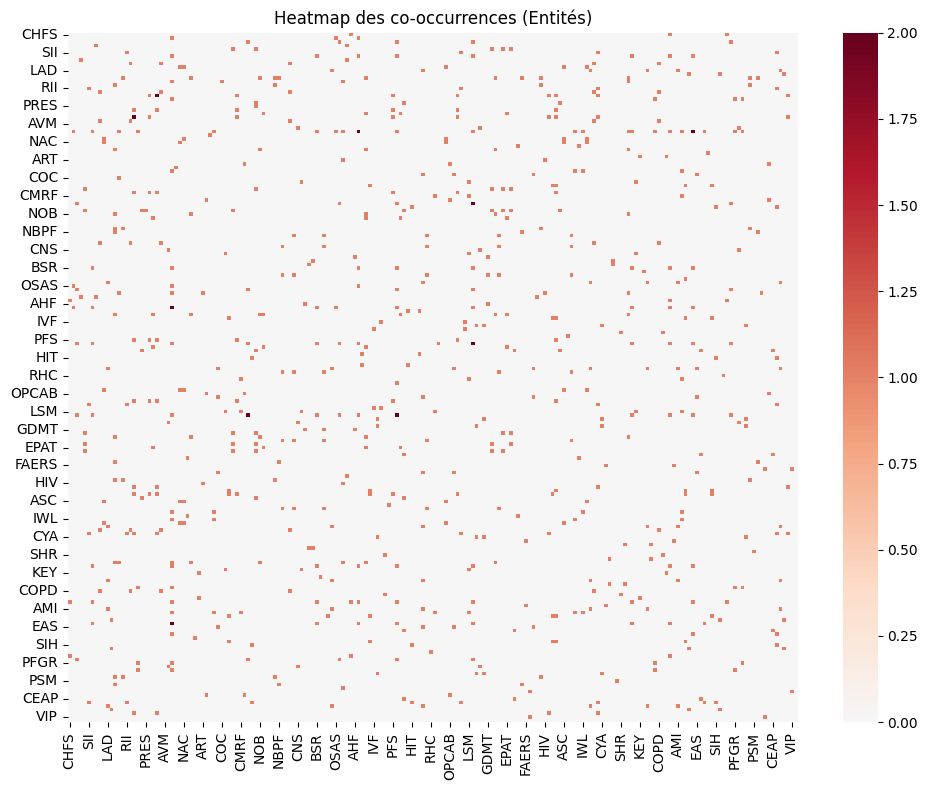

In [90]:
heatmap_cooccurrences(df, "Entités")

Colonne : Facteurs_cliniques | Entités uniques : 14 | Co-occurrences totales : 302


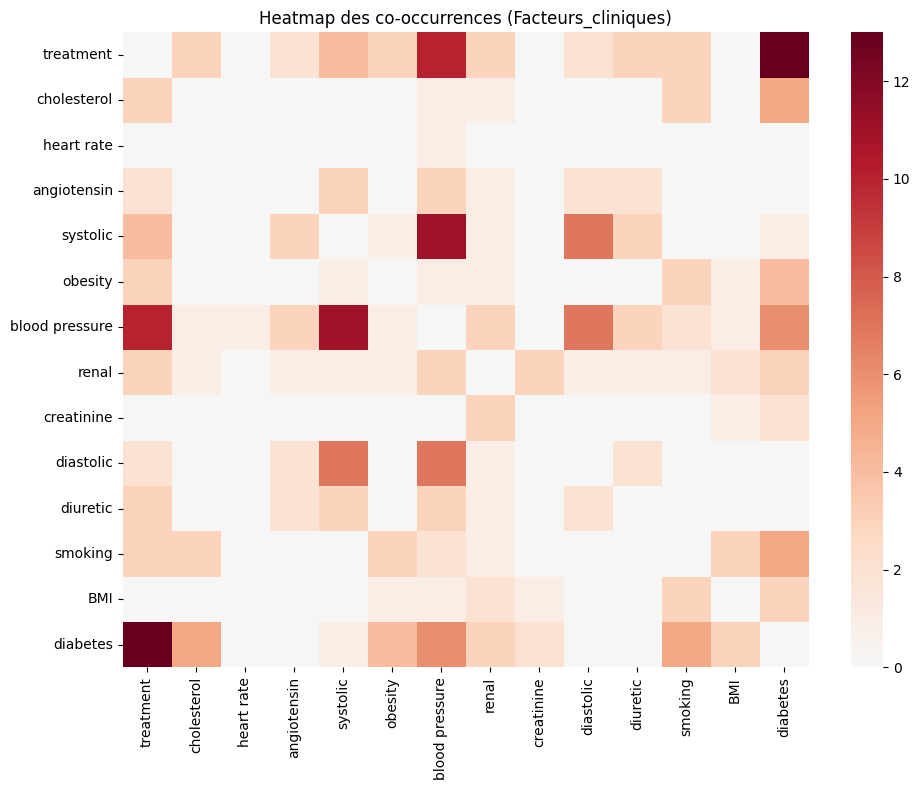

In [91]:
heatmap_cooccurrences(df, "Facteurs_cliniques")


Colonne : Espèces | Entités uniques : 7 | Co-occurrences totales : 470


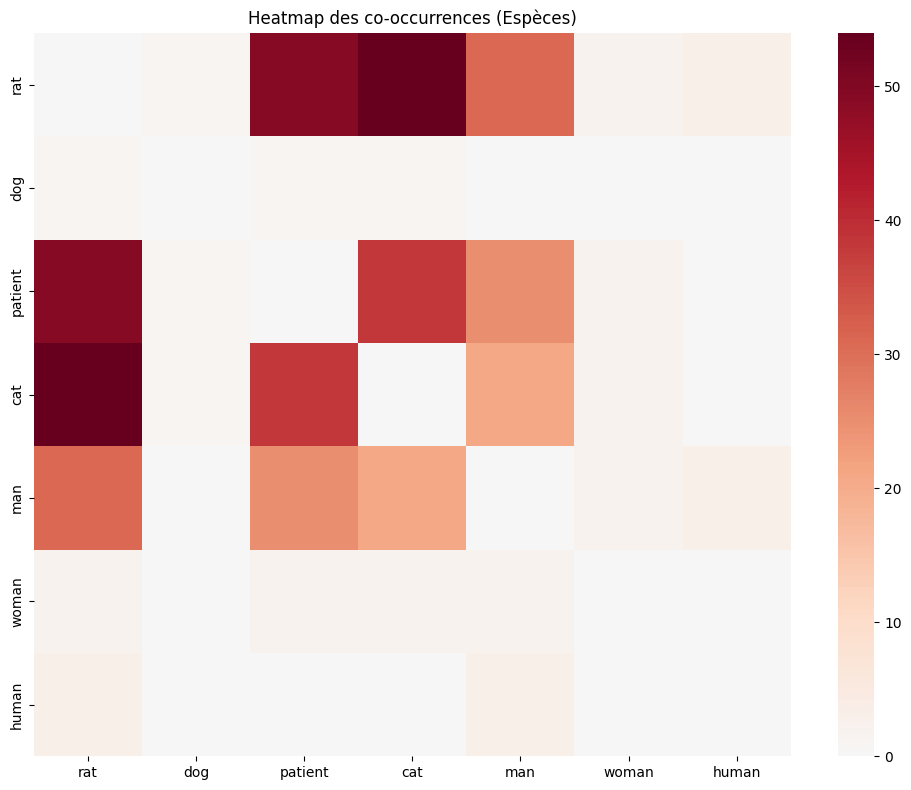

In [92]:
heatmap_cooccurrences(df, "Espèces")


# 4.2 Graphique interactif Plotly (évolution temporelle)

In [93]:
import plotly.express as px
import pandas as pd
import logging

logging.basicConfig(filename="visualisation.log", level=logging.INFO)

def plotly_evolution(df):
    """
    Graphique interactif de l’évolution temporelle des publications.
    - Affiche la figure interactive
    - Sauvegarde en PDF (vectoriel) via kaleido
    """
    try:
        df["Année"] = pd.to_numeric(df["Année"], errors="coerce")
        evolution = df.groupby("Année").size().reset_index(name="Nombre_publications")

        fig = px.line(
            evolution,
            x="Année",
            y="Nombre_publications",
            markers=True,
            title="Évolution temporelle des publications"
        )

        # Sauvegarde en PDF
        fig.write_image("evolution_publications.pdf", format="pdf", width=800, height=600, scale=2)

        # Affichage interactif
        fig.show()

        logging.info("Graphique interactif Plotly généré et sauvegardé en PDF avec succès.")
    except Exception as e:
        logging.error(f"Erreur plotly_evolution : {e}")


# 4.3 Options de visualisations complémentaires

/tmp/ipykernel_1591/1719497471.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(counts), y=list(entites), palette="viridis")


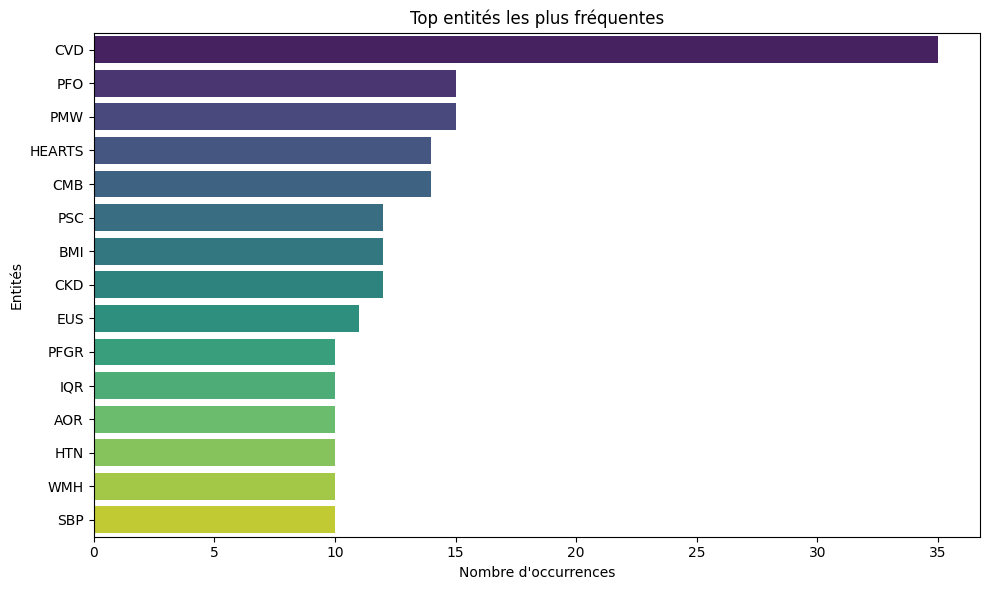

In [94]:
# Barplot des entités les plus fréquentes
import seaborn as sns
import matplotlib.pyplot as plt

def barplot_entites(df, col="Entités", n=15):
    all_entities = sum(df[col].dropna(), [])
    counter = Counter(all_entities)
    top_entities = counter.most_common(n)

    entites, counts = zip(*top_entities)
    plt.figure(figsize=(10,6))
    sns.barplot(x=list(counts), y=list(entites), palette="viridis")
    plt.title("Top entités les plus fréquentes")
    plt.xlabel("Nombre d'occurrences")
    plt.ylabel("Entités")
    plt.tight_layout()
    plt.savefig("barplot_entites.pdf", dpi=300, bbox_inches="tight", format="pdf")
    plt.show()
barplot_entites(df, col="Entités")  # génère barplot_entites.pdf

In [95]:
# Histogramme du nombre d’entités par résumé
def histogram_entites(df, col="Entités"):
    df["Nb_entites"] = df[col].apply(len)
    plt.figure(figsize=(8,5))
    plt.hist(df["Nb_entites"], bins=20, color="skyblue", edgecolor="black")
    plt.title("Distribution du nombre d’entités par résumé")
    plt.xlabel("Nombre d’entités")
    plt.ylabel("Fréquence")
    plt.tight_layout()
    plt.savefig("histogram_entites.pdf", dpi=300, bbox_inches="tight", format="pdf")
    plt.show()


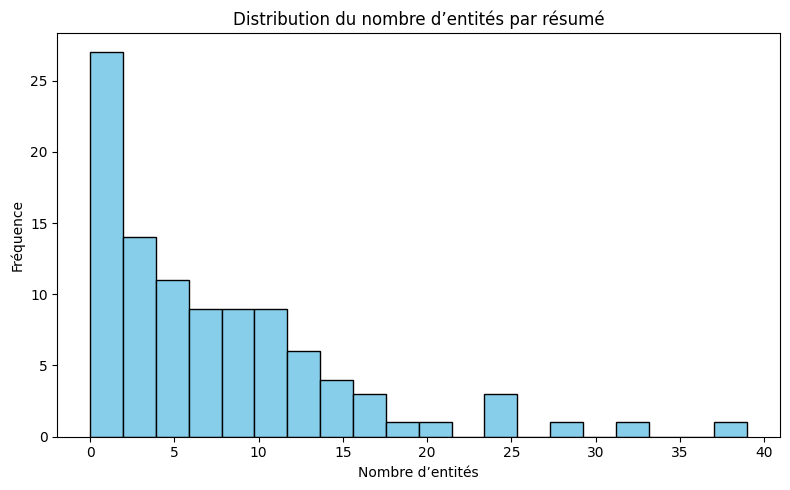

In [96]:
histogram_entites(df, col="Entités")  # génère histogram_entites.pdf

In [97]:
# Boxplot pour comparer la variabilité
def boxplot_entites(df, col="Entités"):
    df["Nb_entites"] = df[col].apply(len)
    plt.figure(figsize=(6,5))
    sns.boxplot(y=df["Nb_entites"], color="lightgreen")
    plt.title("Variabilité du nombre d’entités par résumé")
    plt.ylabel("Nombre d’entités")
    plt.tight_layout()
    plt.savefig("boxplot_entites.pdf", dpi=300, bbox_inches="tight", format="pdf")
    plt.show()


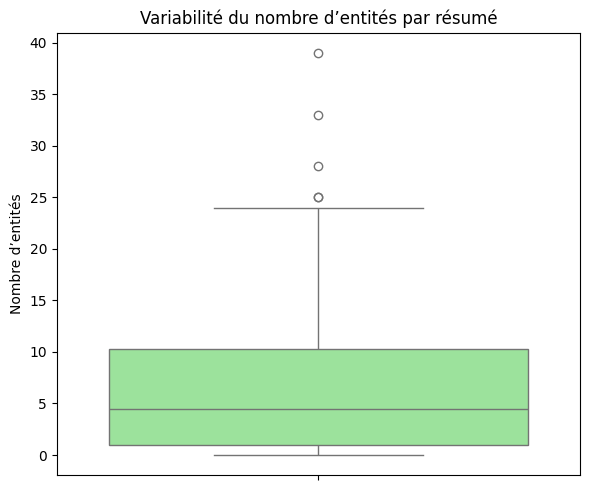

In [98]:
boxplot_entites(df, col="Entités") # génère boxplot_entites.pdf

In [99]:
# Nuage de points (scatter plot)
def scatter_entites(df):
    df["Nb_entites"] = df["Entités"].apply(len)
    plt.figure(figsize=(8,6))
    plt.scatter(df["Année"], df["Nb_entites"], alpha=0.6, color="purple")
    plt.title("Nuage de points : Nb d’entités par année")
    plt.xlabel("Année")
    plt.ylabel("Nombre d’entités")
    plt.tight_layout()
    plt.savefig("scatter_entites.pdf", dpi=300, bbox_inches="tight", format="pdf")
    plt.show()


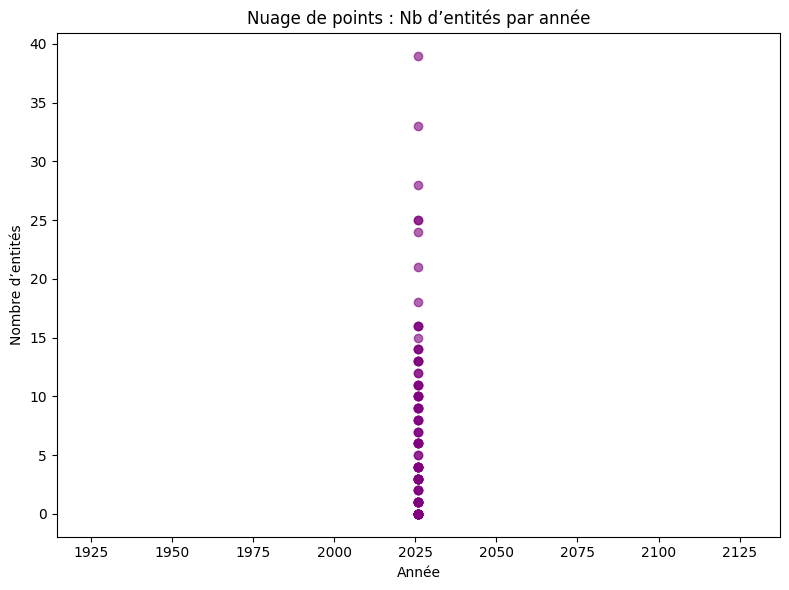

In [100]:
scatter_entites(df)  # génère scatter_entites.pdf

# Creation du fichier README.md

In [101]:
content = """# Projet M2 Bioinformatique – Analyse de publications

##  Description
Ce projet analyse un corpus de publications scientifiques afin d’extraire des entités, calculer des statistiques et produire des visualisations.

##  Organisation du dossier
- code/ : scripts Python
- data/ : données générées (CSV/Parquet)
- figures/ : figures produites (PDF)
- rapport.pdf : court rapport académique
- README.md : ce fichier

## Installation
pip install -U pandas seaborn matplotlib plotly kaleido

##  Exécution
Ce projet s’exécute via un **notebook Jupyter/Google Colab**.

1. Ouvrir le fichier `main.ipynb` dans **Google Colab** ou **Jupyter Notebook**.
2. Exécuter les cellules dans l’ordre pour reproduire les analyses.
3. Les figures générées (PDF) seront automatiquement sauvegardées dans le dossier `figures/`.
4. Les données transformées (CSV/Parquet) seront sauvegardées dans le dossier `data/`.

##  Résultats
- Graphiques interactifs Plotly
- Histogrammes, boxplots, barplots
- Heatmaps de co-occurrences

##  Auteur
Samba NDONGO – Master 2 Bioinformatique
"""
with open("README.md", "w") as f:
    f.write(content)


In [102]:
# Lecture et affichage du contenu
with open("README.md", "r") as f:
    print(f.read())


# Projet M2 Bioinformatique – Analyse de publications

##  Description
Ce projet analyse un corpus de publications scientifiques afin d’extraire des entités, calculer des statistiques et produire des visualisations.

##  Organisation du dossier
- code/ : scripts Python
- data/ : données générées (CSV/Parquet)
- figures/ : figures produites (PDF)
- rapport.pdf : court rapport académique
- README.md : ce fichier

## Installation
pip install -U pandas seaborn matplotlib plotly kaleido

##  Exécution
Ce projet s’exécute via un **notebook Jupyter/Google Colab**.

1. Ouvrir le fichier `main.ipynb` dans **Google Colab** ou **Jupyter Notebook**.
2. Exécuter les cellules dans l’ordre pour reproduire les analyses.
3. Les figures générées (PDF) seront automatiquement sauvegardées dans le dossier `figures/`.
4. Les données transformées (CSV/Parquet) seront sauvegardées dans le dossier `data/`.

##  Résultats
- Graphiques interactifs Plotly
- Histogrammes, boxplots, barplots
- Heatmaps de co-occurr